# Classificação de uso e cobertura do solo com EuroSAT

**Disciplina:** Deep Learning - Unisinos - 2026/2  
**Tarefa 2:** Projeto prático  
**Grupo:** Grupo 22

**Integrantes:**

- Guilherme Zanini da Silva
- Diego Arruda Torales



## 1. Problema, objetivo e pergunta de pesquisa

Imagens de sensoriamento remoto permitem observar padrões de uso e cobertura do solo em grande escala. Automatizar sua classificação pode apoiar estudos ambientais, planejamento territorial e acompanhamento de mudanças na paisagem. Neste trabalho, a tarefa é atribuir uma entre dez classes a cada imagem RGB do EuroSAT.

Pergunta que orienta os experimentos:

**Em que medida uma CNN treinada do zero e uma ResNet50 pré-treinada conseguem distinguir as dez classes do EuroSAT, e como diferentes hiperparâmetros afetam o desempenho e a generalização?**

Os objetivos específicos são:

- caracterizar o dataset e suas classes;
- construir uma CNN própria e analisar profundidade, ativação, regularização, função de erro e otimizador;
- adaptar uma ResNet50 pré-treinada, comparando extração de características e fine-tuning;
- avaliar acurácia, precisão, recall, F1 macro, matrizes de confusão e erros por classe;

## 2. Dataset EuroSAT

O EuroSAT foi construído a partir de imagens do satélite Sentinel-2. A configuração RGB utilizada neste trabalho contém 27.000 imagens de 64 × 64 pixels e dez classes: cultivo anual, floresta, vegetação herbácea, rodovia, área industrial, pastagem, cultivo permanente, área residencial, rio e mar/lago.

A versão RGB é adequada ao escopo porque permite utilizar arquiteturas convolucionais pré-treinadas no ImageNet, que esperam três canais. A escolha implica uma limitação: as outras bandas espectrais do Sentinel-2 não são exploradas.

**Referências:**

- Helber, P.; Bischke, B.; Dengel, A.; Borth, D. *EuroSAT: A Novel Dataset and Deep Learning Benchmark for Land Use and Land Cover Classification*. IEEE JSTARS, 2019. https://arxiv.org/abs/1709.00029
- EuroSAT RGB no Zenodo (fonte dos arquivos). https://zenodo.org/records/7711810
- TensorFlow Datasets, catálogo e descrição do EuroSAT. https://www.tensorflow.org/datasets/catalog/eurosat
- Kaggle, EuroSAT Dataset. https://www.kaggle.com/datasets/apollo2506/eurosat-dataset

## 3. Ambiente e reprodutibilidade

O notebook é compatível com Google Colab, mas os resultados incorporados foram gerados em Linux via WSL com uma GPU NVIDIA RTX 3060. O repositório também fornece um ambiente Docker Linux, validado com TensorFlow 2.20 e acesso efetivo à mesma GPU, para novas execuções reproduzíveis. Sementes são fixadas para reduzir variações; pequenas diferenças ainda podem ocorrer por paralelismo, hardware e versões das bibliotecas.

In [1]:
# No Google Colab, descomente se alguma dependência estiver ausente.
# !pip install -q scikit-learn seaborn

import json
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from tensorflow import keras
from tensorflow.keras import layers, regularizers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# True executa a matriz completa exigida no trabalho.
EXECUTAR_EXPERIMENTOS = True

# A variável de ambiente permite uma verificação técnica curta sem alterar
# a configuração entregue. Na execução completa, seu valor deve permanecer 0.
MODO_VALIDACAO_RAPIDA = os.getenv("EUROSAT_QUICK_RUN", "0") == "1"

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
FIGURES_DIR = PROJECT_ROOT / "figures"
RESULTS_DIR = PROJECT_ROOT / "results"
MODELS_DIR = PROJECT_ROOT / "models"
for directory in (FIGURES_DIR, RESULTS_DIR, MODELS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU(s):", tf.config.list_physical_devices("GPU"))
print("Modo de validação rápida:", MODO_VALIDACAO_RAPIDA)
print("Diretório do projeto:", PROJECT_ROOT.resolve())

TensorFlow: 2.20.0
GPU(s): [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Modo de validação rápida: False
Diretório do projeto: /workspace


2026-11-16 23:52:44.367407: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:981] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-11-16 23:52:44.402612: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:981] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-11-16 23:52:44.402827: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:981] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.


## 4. Aquisição e separação dos dados

O arquivo RGB oficial é obtido do repositório científico Zenodo e armazenado no cache do Keras, fora deste projeto. Os caminhos são separados de forma estratificada e determinística em **70% para treino, 15% para validação e 15% para teste**.

- **Treino (18.900 imagens):** quantidade suficiente para ajustar os pesos das duas famílias de redes.
- **Validação (4.050 imagens):** usada exclusivamente para comparar arquiteturas e hiperparâmetros.
- **Teste (4.050 imagens):** consultado uma única vez, depois da seleção dos modelos.

A proporção 70/15/15 preserva a maior parte dos dados para aprendizado e mantém validação e teste suficientemente grandes para estimar métricas por classe. Separar validação e teste evita selecionar hiperparâmetros com base no resultado final.

In [2]:
DATASET_URL = (
    "https://zenodo.org/api/records/7711810/files/"
    "EuroSAT_RGB.zip/content"
)
archive_path = Path(
    keras.utils.get_file(
        fname="EuroSAT_RGB.zip",
        origin=DATASET_URL,
        file_hash="f46e308c4d50d4bf32fedad2d3d62f3b",
        hash_algorithm="md5",
        extract=True,
    )
)
extraction_candidates = [
    archive_path.parent / "EuroSAT_RGB_extracted" / "EuroSAT_RGB",
    archive_path.parent / "EuroSAT_RGB",
]
dataset_root = next(
    (path for path in extraction_candidates if path.exists()), None
)
if dataset_root is None:
    raise FileNotFoundError(
        f"Pasta extraída não encontrada em: {extraction_candidates}"
    )

CLASS_NAMES = sorted(path.name for path in dataset_root.iterdir() if path.is_dir())
NUM_CLASSES = len(CLASS_NAMES)
IMAGE_SHAPE = (64, 64, 3)
class_to_index = {name: index for index, name in enumerate(CLASS_NAMES)}

all_paths = []
all_labels = []
for class_name in CLASS_NAMES:
    class_paths = sorted((dataset_root / class_name).glob("*.jpg"))
    all_paths.extend(str(path) for path in class_paths)
    all_labels.extend([class_to_index[class_name]] * len(class_paths))

train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    all_paths,
    all_labels,
    test_size=0.30,
    random_state=SEED,
    stratify=all_labels,
)
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_labels,
)

def build_raw_dataset(paths, labels):
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    def load_jpeg(path, label):
        image = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
        image = tf.ensure_shape(image, IMAGE_SHAPE)
        return image, label
    return dataset.map(load_jpeg, num_parallel_calls=tf.data.AUTOTUNE)

if MODO_VALIDACAO_RAPIDA:
    # Apenas para validar sintaxe e fluxo local. Não usar estes resultados
    # como entrega acadêmica.
    train_paths, train_labels = train_paths[:1_600], train_labels[:1_600]
    val_paths, val_labels = val_paths[:500], val_labels[:500]
    test_paths, test_labels = test_paths[:500], test_labels[:500]

train_raw = build_raw_dataset(train_paths, train_labels)
val_raw = build_raw_dataset(val_paths, val_labels)
test_raw = build_raw_dataset(test_paths, test_labels)

print("Classes:", CLASS_NAMES)
print("Quantidade de classes:", NUM_CLASSES)
print("Formato original:", IMAGE_SHAPE)

94658721/94658721 ━━━━━━━━━━━━━━━━━━━━ 112s 1us/step
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Quantidade de classes: 10
Formato original: (64, 64, 3)


2026-11-21 01:53:25.027172: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
I0000 00:00:1795226005.027233     136 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9704 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:01:00.0, compute capability: 8.6


In [3]:
def count_labels(dataset):
    counts = np.zeros(NUM_CLASSES, dtype=int)
    total = 0
    for _, labels in dataset.batch(512).as_numpy_iterator():
        counts += np.bincount(labels, minlength=NUM_CLASSES)
        total += len(labels)
    return counts, total


split_counts = {}
for split_name, dataset in {
    "Treino": train_raw,
    "Validação": val_raw,
    "Teste": test_raw,
}.items():
    counts, total = count_labels(dataset)
    split_counts[split_name] = counts
    print(f"{split_name}: {total:,} imagens")

distribution_df = pd.DataFrame(split_counts, index=CLASS_NAMES)
distribution_df.index.name = "Classe"
distribution_df.loc["Total"] = distribution_df.sum(axis=0)
display(distribution_df)
distribution_df.to_csv(RESULTS_DIR / "distribuicao_classes_por_split.csv")

Treino: 18,900 imagens
Validação: 4,050 imagens
Teste: 4,050 imagens


,Treino,Validação,Teste
Classe,,,
AnnualCrop,2100,450,450
Forest,2100,450,450
HerbaceousVegetation,2100,450,450
Highway,1750,375,375
Industrial,1750,375,375
Pasture,1400,300,300
PermanentCrop,1750,375,375
Residential,2100,450,450
River,1750,375,375


### 4.1 Distribuição e amostras

Uma distribuição semelhante entre os subconjuntos reduz o risco de avaliar um modelo em uma composição muito diferente daquela usada no treinamento. As amostras também permitem verificar visualmente a natureza do problema: algumas classes possuem texturas muito características, enquanto outras apresentam padrões visualmente próximos.

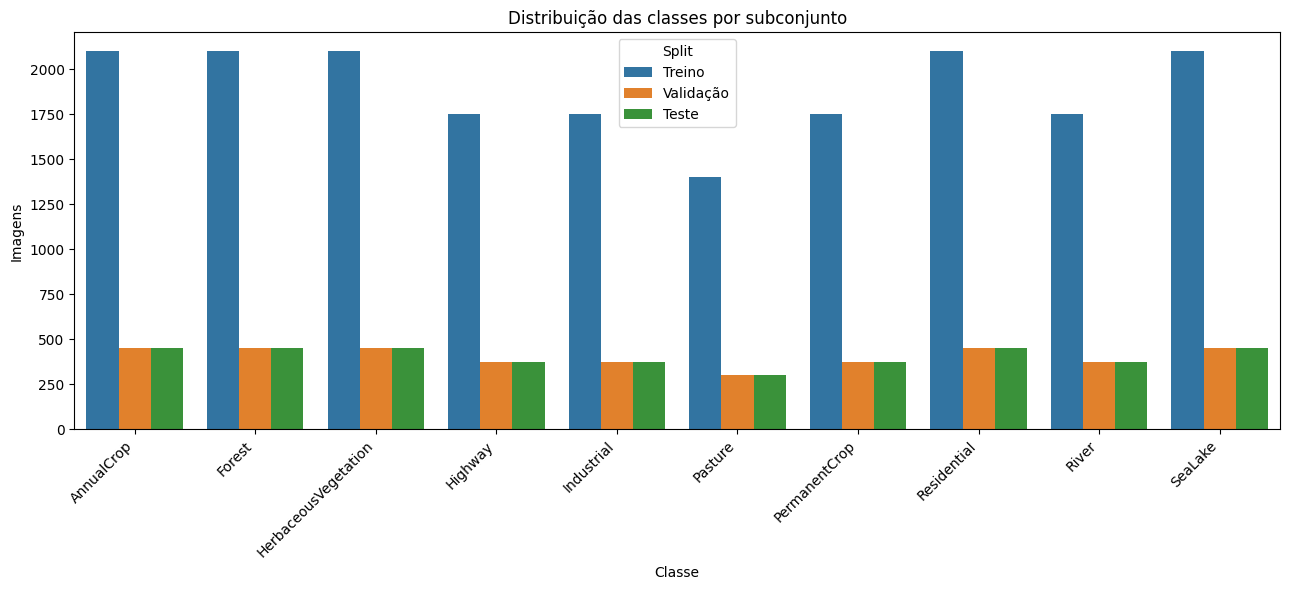

In [4]:
plot_df = distribution_df.drop(index="Total").reset_index().melt(
    id_vars="Classe", var_name="Split", value_name="Imagens"
)
plt.figure(figsize=(13, 6))
sns.barplot(data=plot_df, x="Classe", y="Imagens", hue="Split")
plt.title("Distribuição das classes por subconjunto")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "distribuicao_classes.png", dpi=160, bbox_inches="tight")
plt.show()

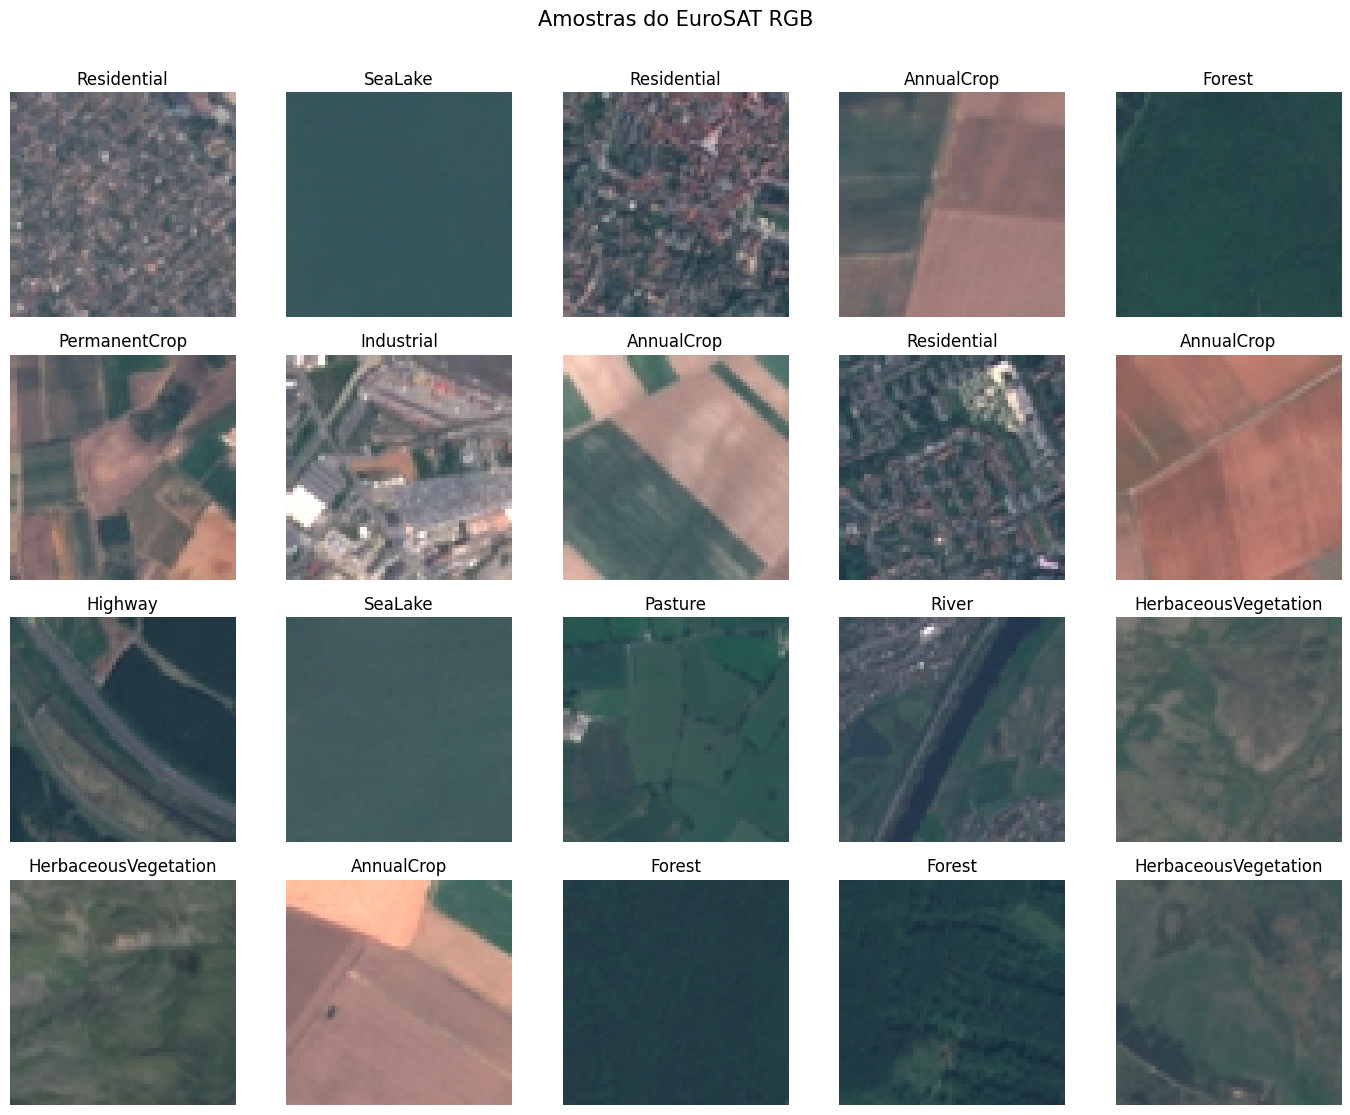

In [5]:
sample_images, sample_labels = next(iter(train_raw.batch(20)))
plt.figure(figsize=(14, 11))
for i in range(20):
    ax = plt.subplot(4, 5, i + 1)
    ax.imshow(sample_images[i].numpy())
    ax.set_title(CLASS_NAMES[int(sample_labels[i])])
    ax.axis("off")
plt.suptitle("Amostras do EuroSAT RGB", y=1.01, fontsize=15)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "amostras_eurosat.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. Pré-processamento e data augmentation

As imagens originais possuem 64 × 64 pixels e valores inteiros entre 0 e 255. Na CNN própria, `Rescaling(1/255)` converte os pixels para `[0, 1]`, o que melhora a escala numérica usada pelos otimizadores. Na ResNet50, `preprocess_input` é obrigatório para reproduzir a centralização e a escala utilizadas no pré-treinamento do ImageNet.

Na ResNet50, as imagens são interpoladas para **128 × 128**. A arquitetura aceita entradas a partir de 32 × 32; 128 × 128 foi escolhido como compromisso entre resolução espacial e custo. Usar 224 × 224 aumentaria aproximadamente três vezes a quantidade de pixels processados, mas não criaria detalhes que não existem nas imagens originais de 64 × 64.

O aumento de dados aplica espelhamentos, rotações, zoom e contraste somente durante o treino. Essas operações são coerentes com cenas de satélite: a classe não depende da orientação da imagem, e pequenas diferenças geométricas ou de iluminação devem preservar o rótulo. Elas também reduzem a memorização de recortes específicos.

O **batch size 128** aproveitou a memória disponível da RTX 3060 e reduziu o tempo por época; lotes maiores também produzem gradientes menos ruidosos. Em outro ambiente com menos memória de GPU, como algumas sessões do Colab, ele pode ser reduzido para 64 sem alterar a arquitetura. `cache`, `prefetch` e paralelismo automático evitam que a leitura dos JPEGs deixe a GPU ociosa.

In [6]:
BATCH_SIZE = 128 if not MODO_VALIDACAO_RAPIDA else 32
AUTOTUNE = tf.data.AUTOTUNE


def prepare_dataset(dataset, training=False):
    # O conjunto RGB ocupa cerca de 330 MB e cabe confortavelmente em
    # memória. O cache elimina a leitura de milhares de JPEGs a cada época.
    dataset = dataset.cache()
    if training:
        dataset = dataset.shuffle(4096, seed=SEED, reshuffle_each_iteration=True)
    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_ds = prepare_dataset(train_raw, training=True)
val_ds = prepare_dataset(val_raw)
test_ds = prepare_dataset(test_raw)

data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal_and_vertical", seed=SEED),
        layers.RandomRotation(0.12, seed=SEED),
        layers.RandomZoom(0.10, seed=SEED),
        layers.RandomContrast(0.10, seed=SEED),
    ],
    name="data_augmentation",
)

## 6. Estratégia experimental e justificativa dos hiperparâmetros

Cada configuração é treinada com `EarlyStopping`, que interrompe o ajuste após três épocas sem melhora de `val_loss` e restaura os melhores pesos. `ReduceLROnPlateau` reduz a taxa de aprendizado quando a validação estagna, permitindo ajustes mais finos sem definir manualmente o momento da redução.

As configurações foram escolhidas para cobrir alternativas solicitadas no enunciado:

- **profundidade e filtros:** três ou quatro blocos, avaliando capacidade e custo;
- **ReLU e ELU:** ReLU é a referência simples e eficiente; ELU testa ativações negativas suaves;
- **Batch Normalization:** avalia estabilização das ativações e dos gradientes;
- **dropout, L2 e label smoothing:** mecanismos complementares contra sobreajuste e confiança excessiva;
- **Adam, RMSprop e SGD com momentum:** comparam métodos adaptativos e otimização clássica;
- **Sparse CE e CE com label smoothing:** comparam alvos rígidos e suavizados.

Adam com `1e-3` é usado como baseline. Taxas `5e-4` são usadas nas configurações mais regularizadas para atualizações mais conservadoras; SGD usa `1e-2` com momentum porque normalmente requer taxa maior. No fine-tuning, `1e-5` reduz o risco de destruir representações úteis do ImageNet.

A comparação utiliza F1 macro, acurácia de validação, parâmetros treináveis, épocas e tempo. O F1 macro é o critério principal porque atribui o mesmo peso a cada classe. Como algumas configurações alteram vários componentes simultaneamente, os resultados medem o efeito do **conjunto de escolhas**; não são tratados como prova causal isolada de um único hiperparâmetro.

In [7]:
def make_optimizer(name, learning_rate):
    optimizers = {
        "Adam": keras.optimizers.Adam,
        "RMSprop": keras.optimizers.RMSprop,
        "SGD": lambda learning_rate: keras.optimizers.SGD(
            learning_rate=learning_rate, momentum=0.9, nesterov=True
        ),
    }
    return optimizers[name](learning_rate=learning_rate)


@keras.utils.register_keras_serializable(package="EuroSAT")
def smoothed_sparse_ce(y_true, y_pred):
    y_true = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
    y_one_hot = tf.one_hot(y_true, depth=NUM_CLASSES)
    return keras.losses.categorical_crossentropy(
        y_one_hot, y_pred, label_smoothing=0.10
    )


def compile_model(model, config):
    loss = (
        smoothed_sparse_ce
        if config.get("label_smoothing", False)
        else keras.losses.SparseCategoricalCrossentropy()
    )
    model.compile(
        optimizer=make_optimizer(config["optimizer"], config["learning_rate"]),
        loss=loss,
        metrics=["accuracy"],
    )
    return model


def dataset_targets(dataset):
    return np.concatenate([labels.numpy() for _, labels in dataset], axis=0)


y_val = dataset_targets(val_ds)
y_test = dataset_targets(test_ds)


def train_experiment(model, config, family, max_epochs):
    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=3, restore_best_weights=True, verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.3, patience=1, min_lr=1e-7, verbose=1
        ),
    ]
    start = time.perf_counter()
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=max_epochs,
        callbacks=callbacks,
        verbose=2,
    )
    elapsed = time.perf_counter() - start
    val_prob = model.predict(val_ds, verbose=0)
    val_pred = np.argmax(val_prob, axis=1)
    values = {
        "familia": family,
        "experimento": config["id"],
        "descricao": config["description"],
        "camadas_filtros": str(config.get("filters", "ResNet50")),
        "ativacao": config.get("activation", "relu"),
        "regularizacao": config.get("regularization", "-") ,
        "funcao_erro": "CE + label smoothing" if config.get("label_smoothing") else "Sparse CE",
        "otimizador": config["optimizer"],
        "taxa_aprendizado": config["learning_rate"],
        "parametros_totais": model.count_params(),
        "parametros_treinaveis": int(sum(np.prod(v.shape) for v in model.trainable_weights)),
        "epocas_executadas": len(history.history["loss"]),
        "melhor_val_loss": float(np.min(history.history["val_loss"])),
        "melhor_val_accuracy": float(np.max(history.history["val_accuracy"])),
        "val_f1_macro": float(f1_score(y_val, val_pred, average="macro")),
        "tempo_segundos": round(elapsed, 1),
    }
    return history, values


def plot_history(history, title, filename):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].plot(history.history["loss"], label="treino")
    axes[0].plot(history.history["val_loss"], label="validação")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Época")
    axes[0].legend()
    axes[1].plot(history.history["accuracy"], label="treino")
    axes[1].plot(history.history["val_accuracy"], label="validação")
    axes[1].set_title("Acurácia")
    axes[1].set_xlabel("Época")
    axes[1].legend()
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()

## 7. Família 1 - CNN treinada do zero

A CNN própria alterna convolução e max pooling. À medida que a profundidade aumenta, os mapas de características passam de padrões locais simples para combinações mais abstratas. `GlobalAveragePooling2D` reduz parâmetros em comparação com uma camada `Flatten` extensa.

A matriz experimental altera:

- três ou quatro blocos convolucionais;
- quantidade de filtros;
- ReLU ou ELU;
- Batch Normalization;
- dropout e regularização L2;
- cross-entropy padrão ou com label smoothing;
- Adam, RMSprop e SGD.

In [8]:
SCRATCH_CONFIGS = [
    {
        "id": "CNN-1",
        "description": "Baseline com três blocos",
        "filters": [32, 64, 128],
        "dense_units": 128,
        "activation": "relu",
        "batch_norm": False,
        "dropout": 0.30,
        "l2": 0.0,
        "optimizer": "Adam",
        "learning_rate": 1e-3,
        "label_smoothing": False,
        "regularization": "Dropout 0,30",
    },
    {
        "id": "CNN-2",
        "description": "Mais profunda, BatchNorm e L2",
        "filters": [32, 64, 128, 256],
        "dense_units": 192,
        "activation": "relu",
        "batch_norm": True,
        "dropout": 0.40,
        "l2": 1e-4,
        "optimizer": "RMSprop",
        "learning_rate": 5e-4,
        "label_smoothing": False,
        "regularization": "BatchNorm + L2 1e-4 + Dropout 0,40",
    },
    {
        "id": "CNN-3",
        "description": "ELU, BatchNorm e label smoothing",
        "filters": [32, 64, 128],
        "dense_units": 256,
        "activation": "elu",
        "batch_norm": True,
        "dropout": 0.50,
        "l2": 1e-4,
        "optimizer": "Adam",
        "learning_rate": 5e-4,
        "label_smoothing": True,
        "regularization": "BatchNorm + L2 1e-4 + Dropout 0,50",
    },
    {
        "id": "CNN-4",
        "description": "Rede compacta treinada com SGD",
        "filters": [32, 64, 96],
        "dense_units": 128,
        "activation": "relu",
        "batch_norm": True,
        "dropout": 0.35,
        "l2": 5e-5,
        "optimizer": "SGD",
        "learning_rate": 1e-2,
        "label_smoothing": False,
        "regularization": "BatchNorm + L2 5e-5 + Dropout 0,35",
    },
]


def build_scratch_cnn(config):
    reg = regularizers.l2(config["l2"]) if config["l2"] else None
    inputs = keras.Input(shape=IMAGE_SHAPE, name="image")
    x = data_augmentation(inputs)
    x = layers.Rescaling(1.0 / 255)(x)
    for block_index, filters in enumerate(config["filters"], start=1):
        x = layers.Conv2D(
            filters,
            3,
            padding="same",
            use_bias=not config["batch_norm"],
            kernel_regularizer=reg,
            name=f"conv_{block_index}",
        )(x)
        if config["batch_norm"]:
            x = layers.BatchNormalization(name=f"bn_{block_index}")(x)
        x = layers.Activation(config["activation"])(x)
        x = layers.MaxPooling2D(name=f"pool_{block_index}")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(
        config["dense_units"],
        activation=config["activation"],
        kernel_regularizer=reg,
    )(x)
    x = layers.Dropout(config["dropout"])(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="classificacao")(x)
    model = keras.Model(inputs, outputs, name=config["id"])
    return compile_model(model, config)

In [9]:
scratch_models = {}
scratch_histories = {}
scratch_results = []

if EXECUTAR_EXPERIMENTOS:
    scratch_epochs = 2 if MODO_VALIDACAO_RAPIDA else 12
    for config in SCRATCH_CONFIGS:
        print("\n" + "=" * 90)
        print(config["id"], "-", config["description"])
        model = build_scratch_cnn(config)
        history, result = train_experiment(
            model, config, family="CNN do zero", max_epochs=scratch_epochs
        )
        scratch_models[config["id"]] = model
        scratch_histories[config["id"]] = history
        scratch_results.append(result)

scratch_results_df = pd.DataFrame(scratch_results).sort_values(
    "val_f1_macro", ascending=False
)
display(scratch_results_df)
scratch_results_df.to_csv(
    RESULTS_DIR / "experimentos_cnn_zero.csv", index=False
)


CNN-1 - Baseline com três blocos
Epoch 1/12
148/148 - 9s - 59ms/step - accuracy: 0.3110 - loss: 1.7798 - val_accuracy: 0.3548 - val_loss: 1.6328 - learning_rate: 1.0000e-03
Epoch 2/12
148/148 - 3s - 24ms/step - accuracy: 0.4824 - loss: 1.3901 - val_accuracy: 0.5709 - val_loss: 1.2038 - learning_rate: 1.0000e-03
Epoch 3/12
148/148 - 3s - 23ms/step - accuracy: 0.5525 - loss: 1.2191 - val_accuracy: 0.5807 - val_loss: 1.1079 - learning_rate: 1.0000e-03
Epoch 4/12
148/148 - 5s - 36ms/step - accuracy: 0.6028 - loss: 1.0760 - val_accuracy: 0.6415 - val_loss: 0.9863 - learning_rate: 1.0000e-03
Epoch 5/12
148/148 - 3s - 23ms/step - accuracy: 0.6483 - loss: 0.9639 - val_accuracy: 0.6719 - val_loss: 0.9179 - learning_rate: 1.0000e-03
Epoch 6/12
148/148 - 3s - 23ms/step - accuracy: 0.6738 - loss: 0.9010 - val_accuracy: 0.6832 - val_loss: 0.9081 - learning_rate: 1.0000e-03
Epoch 7/12

Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
148/148 - 3s - 23ms/step - accuracy: 0

,familia,experimento,descricao,camadas_filtros,ativacao,regularizacao,funcao_erro,otimizador,taxa_aprendizado,parametros_totais,parametros_treinaveis,epocas_executadas,melhor_val_loss,melhor_val_accuracy,val_f1_macro,tempo_segundos
3,CNN do zero,CNN-4,Rede compacta treinada com SGD,"[32, 64, 96]",relu,"BatchNorm + L2 5e-5 + Dropout 0,35",Sparse CE,SGD,0.0100,89066,88682,12,0.501479,0.834815,0.826796,67.8
1,CNN do zero,CNN-2,"Mais profunda, BatchNorm e L2","[32, 64, 128, 256]",relu,"BatchNorm + L2 1e-4 + Dropout 0,40",Sparse CE,RMSprop,0.0005,441130,440170,8,0.578469,0.815062,0.808161,54.2
0,CNN do zero,CNN-1,Baseline com três blocos,"[32, 64, 128]",relu,"Dropout 0,30",Sparse CE,Adam,0.0010,111050,111050,12,0.772522,0.719259,0.706068,48.4
2,CNN do zero,CNN-3,"ELU, BatchNorm e label smoothing","[32, 64, 128]",elu,"BatchNorm + L2 1e-4 + Dropout 0,50",CE + label smoothing,Adam,0.0005,129514,129066,8,1.249014,0.704691,0.691408,54.9


148/148 - 6s - loss: 1.7801 - accuracy: 0.3026 - val_loss: 1.4619 - val_accuracy: 0.3978 - lr: 0.0010 - 6s/epoch - 44ms/step


Epoch 2/12


148/148 - 3s - loss: 1.4321 - accuracy: 0.4461 - val_loss: 1.2491 - val_accuracy: 0.5279 - lr: 0.0010 - 3s/epoch - 19ms/step


Epoch 3/12


... (91 outputs left out)


Epoch 7: ReduceLROnPlateau reducing learning rate to 8.099999686237424e-05.


148/148 - 3s - loss: 0.5831 - accuracy: 0.8041 - val_loss: 0.8446 - val_accuracy: 0.7284 - lr: 2.7000e-04 - 3s/epoch - 23ms/step


Epoch 7: early stopping


,familia,experimento,descricao,camadas_filtros,ativacao,regularizacao,funcao_erro,otimizador,taxa_aprendizado,parametros_totais,parametros_treinaveis,epocas_executadas,melhor_val_loss,melhor_val_accuracy,val_f1_macro,tempo_segundos
1,CNN do zero,CNN-2,"Mais profunda, BatchNorm e L2","[32, 64, 128, 256]",relu,"BatchNorm + L2 1e-4 + Dropout 0,40",Sparse CE,RMSprop,0.0005,441130,440170,8,0.607982,0.809136,0.800660,34.0
2,CNN do zero,CNN-3,"ELU, BatchNorm e label smoothing","[32, 64, 128]",elu,"BatchNorm + L2 1e-4 + Dropout 0,50",CE + label smoothing,Adam,0.0005,129514,129066,12,1.184400,0.750123,0.746568,46.1
3,CNN do zero,CNN-4,Rede compacta treinada com SGD,"[32, 64, 96]",relu,"BatchNorm + L2 5e-5 + Dropout 0,35",Sparse CE,SGD,0.0100,89066,88682,7,0.761414,0.728395,0.698994,25.9
0,CNN do zero,CNN-1,Baseline com três blocos,"[32, 64, 128]",relu,"Dropout 0,30",Sparse CE,Adam,0.0010,111050,111050,12,0.825823,0.711358,0.689742,38.3


### 7.1 Discussão dos experimentos da CNN

| Configuração | Principais escolhas | F1 macro de validação | Leitura do resultado |
|---|---|---:|---|
| CNN-1 | 3 blocos, ReLU, dropout 0,30, Adam | 0,6897 | Baseline; menor capacidade e ausência de Batch Normalization/L2. |
| CNN-2 | 4 blocos, BatchNorm, L2, dropout 0,40, RMSprop | **0,8007** | Melhor configuração; +11,09 p.p. sobre a baseline. |
| CNN-3 | 3 blocos, ELU, BatchNorm, L2, dropout 0,50, label smoothing, Adam | 0,7466 | Superou a baseline, mas ficou 5,41 p.p. abaixo da CNN-2. |
| CNN-4 | Rede compacta, BatchNorm, L2, dropout 0,35, SGD | 0,6990 | Baixo custo, porém ganho de apenas 0,93 p.p. sobre a baseline. |

A **CNN-2** foi selecionada porque apresentou o maior F1 macro de validação. O resultado sugere que, neste protocolo, a combinação de maior profundidade, Batch Normalization, L2, dropout e RMSprop compensou o aumento de 111 mil para 440 mil parâmetros treináveis. A CNN-3 mostra que ELU, regularização mais forte e label smoothing melhoraram a baseline, mas não substituíram a capacidade adicional da CNN-2. A CNN-4 foi a mais rápida e compacta, porém o SGD e a menor quantidade de filtros não alcançaram o mesmo desempenho.

Não é possível atribuir os 11,09 pontos de ganho a um único componente, pois a matriz compara combinações. A conclusão válida é que o pacote de escolhas da CNN-2 foi o mais eficiente entre os conjuntos testados. A seleção foi definida antes de consultar o teste.

CNN selecionada: CNN-4


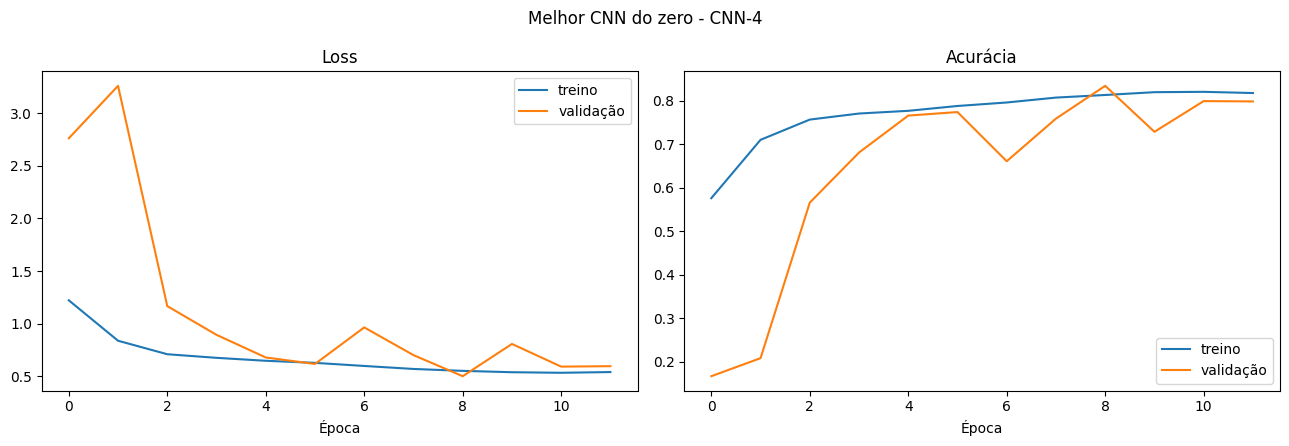

In [10]:
if EXECUTAR_EXPERIMENTOS:
    best_scratch_id = scratch_results_df.iloc[0]["experimento"]
    best_scratch_model = scratch_models[best_scratch_id]
    best_scratch_history = scratch_histories[best_scratch_id]
    print("CNN selecionada:", best_scratch_id)
    plot_history(
        best_scratch_history,
        f"Melhor CNN do zero - {best_scratch_id}",
        "curvas_melhor_cnn_zero.png",
    )

## 8. Família 2 - ResNet50 com transfer learning

A ResNet50 foi escolhida por ser uma arquitetura residual consolidada e explicitamente citada como exemplo no enunciado. Suas conexões de atalho facilitam o fluxo de gradientes, enquanto os pesos do ImageNet oferecem detectores genéricos de bordas, texturas e formas úteis mesmo em imagens de satélite RGB.

A camada classificadora original é removida (`include_top=False`) e substituída por uma cabeça para as dez classes. Na primeira fase, a base permanece congelada para preservar as representações pré-treinadas e reduzir o número de parâmetros ajustados. Comparam-se uma cabeça compacta e outra maior, variando unidades, ativação, dropout, perda e otimizador.

Depois, o melhor modelo congelado passa por fine-tuning. Somente as 30 últimas camadas são liberadas: as camadas iniciais, mais genéricas, permanecem fixas; as camadas finais, mais específicas, podem adaptar-se às texturas do EuroSAT. As camadas de Batch Normalization continuam congeladas para não alterar abruptamente as estatísticas aprendidas no ImageNet.

In [11]:
TRANSFER_CONFIGS = [
    {
        "id": "TL-1",
        "description": "ResNet50 congelada, cabeça compacta",
        "head_units": 128,
        "activation": "relu",
        "dropout": 0.30,
        "optimizer": "Adam",
        "learning_rate": 1e-3,
        "label_smoothing": False,
        "regularization": "Dropout 0,30",
    },
    {
        "id": "TL-2",
        "description": "ResNet50 congelada, cabeça maior e suavização",
        "head_units": 256,
        "activation": "swish",
        "dropout": 0.50,
        "optimizer": "RMSprop",
        "learning_rate": 5e-4,
        "label_smoothing": True,
        "regularization": "Dropout 0,50 + label smoothing",
    },
]


def build_transfer_model(config):
    base_model = keras.applications.ResNet50(
        include_top=False,
        weights="imagenet",
        input_shape=(128, 128, 3),
    )
    base_model.trainable = False

    inputs = keras.Input(shape=IMAGE_SHAPE, name="image")
    x = data_augmentation(inputs)
    x = layers.Resizing(128, 128)(x)
    x = keras.applications.resnet50.preprocess_input(x)
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(config["head_units"], activation=config["activation"])(x)
    x = layers.Dropout(config["dropout"])(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="classificacao")(x)
    model = keras.Model(inputs, outputs, name=config["id"])
    return compile_model(model, config)

In [12]:
transfer_models = {}
transfer_histories = {}
transfer_results = []

if EXECUTAR_EXPERIMENTOS:
    transfer_epochs = 2 if MODO_VALIDACAO_RAPIDA else 8
    for config in TRANSFER_CONFIGS:
        print("\n" + "=" * 90)
        print(config["id"], "-", config["description"])
        model = build_transfer_model(config)
        history, result = train_experiment(
            model, config, family="Transfer learning", max_epochs=transfer_epochs
        )
        transfer_models[config["id"]] = model
        transfer_histories[config["id"]] = history
        transfer_results.append(result)

frozen_results_df = pd.DataFrame(transfer_results).sort_values(
    "val_f1_macro", ascending=False
)
display(frozen_results_df)


TL-1 - ResNet50 congelada, cabeça compacta
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Epoch 1/8
148/148 - 31s - 212ms/step - accuracy: 0.8542 - loss: 0.4501 - val_accuracy: 0.9264 - val_loss: 0.2288 - learning_rate: 1.0000e-03
Epoch 2/8
148/148 - 22s - 146ms/step - accuracy: 0.9191 - loss: 0.2472 - val_accuracy: 0.9331 - val_loss: 0.2089 - learning_rate: 1.0000e-03
Epoch 3/8
148/148 - 22s - 148ms/step - accuracy: 0.9313 - loss: 0.2097 - val_accuracy: 0.9343 - val_loss: 0.1943 - learning_rate: 1.0000e-03
Epoch 4/8
148/148 - 22s - 149ms/step - accuracy: 0.9377 - loss: 0.1852 - val_accuracy: 0.9380 - val_loss: 0.1808 - learning_rate: 1.0000e-03
Epoch 5/8
148/148 - 22s - 147ms/step - accuracy: 0.9399 - loss: 0.1743 - val_accuracy: 0.9440 - val_loss: 0.1691 - learning_rate: 1.0000e-03
Epoch 6/8
148/148 - 22s - 147ms/step - accuracy: 0.9456 - loss: 0.1598 - val_accuracy: 0.9430 - val_loss: 0.1690 - learning_rate: 1.0000e-03
Epoch 7/8

Epoch 7: ReduceLROnPlateau reducing learning rat

,familia,experimento,descricao,camadas_filtros,ativacao,regularizacao,funcao_erro,otimizador,taxa_aprendizado,parametros_totais,parametros_treinaveis,epocas_executadas,melhor_val_loss,melhor_val_accuracy,val_f1_macro,tempo_segundos
0,Transfer learning,TL-1,"ResNet50 congelada, cabeça compacta",ResNet50,relu,"Dropout 0,30",Sparse CE,Adam,0.0010,23851274,263562,8,0.158105,0.949136,0.947780,183.9
1,Transfer learning,TL-2,"ResNet50 congelada, cabeça maior e suavização",ResNet50,swish,"Dropout 0,50 + label smoothing",CE + label smoothing,RMSprop,0.0005,24114826,527114,8,0.659254,0.949136,0.947338,183.4


148/148 - 21s - loss: 0.4459 - accuracy: 0.8579 - val_loss: 0.2409 - val_accuracy: 0.9217 - lr: 0.0010 - 21s/epoch - 141ms/step


Epoch 2/8


148/148 - 14s - loss: 0.2461 - accuracy: 0.9176 - val_loss: 0.2106 - val_accuracy: 0.9319 - lr: 0.0010 - 14s/epoch - 97ms/step


Epoch 3/8


... (29 outputs left out)

148/148 - 14s - loss: 0.6858 - accuracy: 0.9461 - val_loss: 0.6707 - val_accuracy: 0.9477 - lr: 1.5000e-04 - 14s/epoch - 97ms/step


Epoch 8/8


148/148 - 14s - loss: 0.6792 - accuracy: 0.9504 - val_loss: 0.6670 - val_accuracy: 0.9484 - lr: 4.5000e-05 - 14s/epoch - 97ms/step


,familia,experimento,descricao,camadas_filtros,ativacao,regularizacao,funcao_erro,otimizador,taxa_aprendizado,parametros_totais,parametros_treinaveis,epocas_executadas,melhor_val_loss,melhor_val_accuracy,val_f1_macro,tempo_segundos
0,Transfer learning,TL-1,"ResNet50 congelada, cabeça compacta",ResNet50,relu,"Dropout 0,30",Sparse CE,Adam,0.0010,23851274,263562,8,0.154476,0.948642,0.946823,120.3
1,Transfer learning,TL-2,"ResNet50 congelada, cabeça maior e suavização",ResNet50,swish,"Dropout 0,50 + label smoothing",CE + label smoothing,RMSprop,0.0005,24114826,527114,8,0.667015,0.949383,0.946641,118.9


### 8.1 Fine-tuning

O melhor modelo da fase congelada é clonado antes da continuação, preservando a configuração original para uma comparação justa. São liberadas as **30 últimas camadas**, exceto Batch Normalization. Esse número representa um compromisso: oferece capacidade de adaptação nas representações de alto nível sem retreinar toda a ResNet50 e sem aumentar excessivamente o risco de sobreajuste.

A taxa `1e-5` é cem vezes menor que a taxa inicial da TL-1. Atualizações pequenas são necessárias porque os pesos já contêm representações úteis; uma taxa alta poderia causar *catastrophic forgetting*.

In [13]:
if EXECUTAR_EXPERIMENTOS:
    best_frozen_id = frozen_results_df.iloc[0]["experimento"]
    # Clona o modelo vencedor para preservar intacta a configuração
    # congelada na comparação com o fine-tuning.
    frozen_selected_model = transfer_models[best_frozen_id]
    fine_tune_model = keras.models.clone_model(frozen_selected_model)
    fine_tune_model.set_weights(frozen_selected_model.get_weights())
    base_model = fine_tune_model.get_layer("resnet50")
    base_model.trainable = True

    for layer in base_model.layers[:-30]:
        layer.trainable = False
    for layer in base_model.layers[-30:]:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    fine_tune_config = {
        "id": "TL-3",
        "description": f"Fine-tuning das 30 últimas camadas após {best_frozen_id}",
        "activation": "herdada",
        "optimizer": "Adam",
        "learning_rate": 1e-5,
        "label_smoothing": False,
        "regularization": "Configuração herdada + fine-tuning",
    }
    compile_model(fine_tune_model, fine_tune_config)
    fine_epochs = 1 if MODO_VALIDACAO_RAPIDA else 6
    fine_history, fine_result = train_experiment(
        fine_tune_model,
        fine_tune_config,
        family="Transfer learning",
        max_epochs=fine_epochs,
    )
    transfer_models["TL-3"] = fine_tune_model
    transfer_histories["TL-3"] = fine_history
    transfer_results.append(fine_result)

transfer_results_df = pd.DataFrame(transfer_results).sort_values(
    "val_f1_macro", ascending=False
)
display(transfer_results_df)
transfer_results_df.to_csv(
    RESULTS_DIR / "experimentos_transfer_learning.csv", index=False
)

Epoch 1/6
148/148 - 39s - 260ms/step - accuracy: 0.9602 - loss: 0.1188 - val_accuracy: 0.9519 - val_loss: 0.1440 - learning_rate: 1.0000e-05
Epoch 2/6
148/148 - 25s - 171ms/step - accuracy: 0.9632 - loss: 0.1067 - val_accuracy: 0.9548 - val_loss: 0.1390 - learning_rate: 1.0000e-05
Epoch 3/6
148/148 - 25s - 171ms/step - accuracy: 0.9663 - loss: 0.0944 - val_accuracy: 0.9583 - val_loss: 0.1290 - learning_rate: 1.0000e-05
Epoch 4/6

Epoch 4: ReduceLROnPlateau reducing learning rate to 2.9999999242136253e-06.
148/148 - 25s - 171ms/step - accuracy: 0.9703 - loss: 0.0889 - val_accuracy: 0.9556 - val_loss: 0.1413 - learning_rate: 1.0000e-05
Epoch 5/6

Epoch 5: ReduceLROnPlateau reducing learning rate to 8.999999636216671e-07.
148/148 - 25s - 169ms/step - accuracy: 0.9739 - loss: 0.0773 - val_accuracy: 0.9595 - val_loss: 0.1342 - learning_rate: 3.0000e-06
Epoch 6/6

Epoch 6: ReduceLROnPlateau reducing learning rate to 2.6999999249710525e-07.
148/148 - 25s - 169ms/step - accuracy: 0.9746 - loss

,familia,experimento,descricao,camadas_filtros,ativacao,regularizacao,funcao_erro,otimizador,taxa_aprendizado,parametros_totais,parametros_treinaveis,epocas_executadas,melhor_val_loss,melhor_val_accuracy,val_f1_macro,tempo_segundos
2,Transfer learning,TL-3,Fine-tuning das 30 últimas camadas após TL-1,ResNet50,herdada,Configuração herdada + fine-tuning,Sparse CE,Adam,0.00001,23851274,14692234,6,0.129005,0.959506,0.957017,164.8
0,Transfer learning,TL-1,"ResNet50 congelada, cabeça compacta",ResNet50,relu,"Dropout 0,30",Sparse CE,Adam,0.00100,23851274,263562,8,0.158105,0.949136,0.947780,183.9
1,Transfer learning,TL-2,"ResNet50 congelada, cabeça maior e suavização",ResNet50,swish,"Dropout 0,50 + label smoothing",CE + label smoothing,RMSprop,0.00050,24114826,527114,8,0.659254,0.949136,0.947338,183.4


Epoch 2/6


148/148 - 17s - loss: 0.1251 - accuracy: 0.9567 - val_loss: 0.1395 - val_accuracy: 0.9516 - lr: 1.0000e-05 - 17s/epoch - 113ms/step


Epoch 3/6



Epoch 3: ReduceLROnPlateau reducing learning rate to 2.9999999242136253e-06.


... (5 outputs left out)

Epoch 6/6



Epoch 6: ReduceLROnPlateau reducing learning rate to 8.999999636216671e-07.


148/148 - 17s - loss: 0.0959 - accuracy: 0.9674 - val_loss: 0.1357 - val_accuracy: 0.9560 - lr: 3.0000e-06 - 17s/epoch - 112ms/step


,familia,experimento,descricao,camadas_filtros,ativacao,regularizacao,funcao_erro,otimizador,taxa_aprendizado,parametros_totais,parametros_treinaveis,epocas_executadas,melhor_val_loss,melhor_val_accuracy,val_f1_macro,tempo_segundos
2,Transfer learning,TL-3,Fine-tuning das 30 últimas camadas após TL-1,ResNet50,herdada,Configuração herdada + fine-tuning,Sparse CE,Adam,0.00001,23851274,14692234,6,0.133149,0.956049,0.954482,110.3
0,Transfer learning,TL-1,"ResNet50 congelada, cabeça compacta",ResNet50,relu,"Dropout 0,30",Sparse CE,Adam,0.00100,23851274,263562,8,0.154476,0.948642,0.946823,120.3
1,Transfer learning,TL-2,"ResNet50 congelada, cabeça maior e suavização",ResNet50,swish,"Dropout 0,50 + label smoothing",CE + label smoothing,RMSprop,0.00050,24114826,527114,8,0.667015,0.949383,0.946641,118.9


Modelo de transfer learning selecionado: TL-3


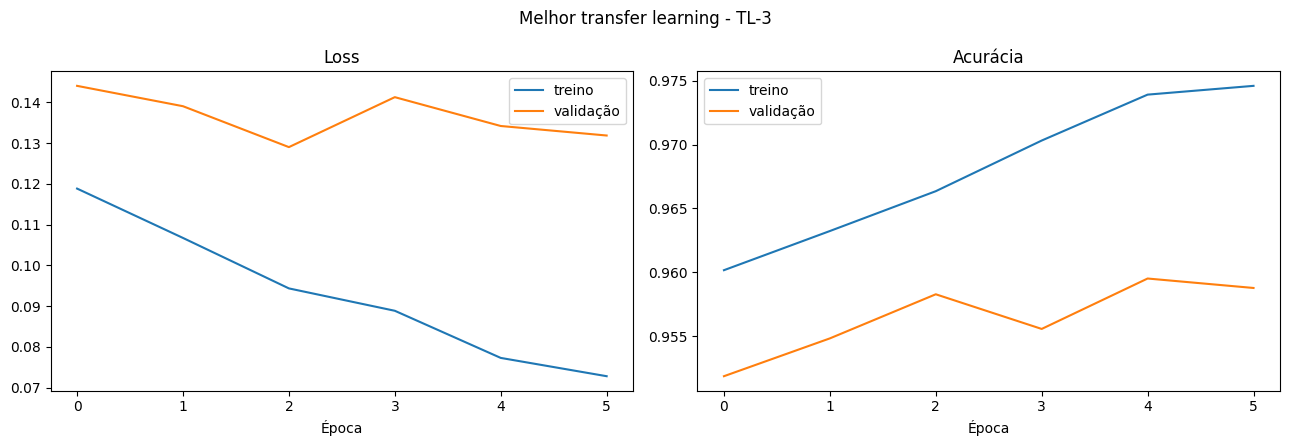

In [14]:
if EXECUTAR_EXPERIMENTOS:
    best_transfer_id = transfer_results_df.iloc[0]["experimento"]
    best_transfer_model = transfer_models[best_transfer_id]
    best_transfer_history = transfer_histories[best_transfer_id]
    print("Modelo de transfer learning selecionado:", best_transfer_id)
    plot_history(
        best_transfer_history,
        f"Melhor transfer learning - {best_transfer_id}",
        "curvas_melhor_transfer_learning.png",
    )

### 8.2 Discussão dos experimentos de transfer learning

| Configuração | Principais escolhas | Parâmetros treináveis | F1 macro de validação |
|---|---|---:|---:|
| TL-1 | Base congelada, 128 unidades, ReLU, dropout 0,30, Adam | 263.562 | 0,9468 |
| TL-2 | Base congelada, 256 unidades, Swish, dropout 0,50, label smoothing, RMSprop | 527.114 | 0,9466 |
| TL-3 | Fine-tuning das últimas 30 camadas da TL-1, Adam `1e-5` | 14.692.234 | **0,9545** |

TL-1 e TL-2 ficaram praticamente empatadas: a cabeça duas vezes maior, o dropout mais forte, Swish, label smoothing e RMSprop da TL-2 adicionaram custo, mas não melhoraram o F1. A diferença de 0,02 p.p. favoreceu a cabeça compacta TL-1, que foi escolhida para a fase seguinte.

O fine-tuning TL-3 elevou o F1 em **0,77 p.p.** sobre TL-1. O ganho é menor que a diferença entre transfer learning e CNN do zero, mas é consistente com a ideia de que as camadas finais se beneficiam de adaptação às texturas e aos padrões espaciais do EuroSAT. O custo é o aumento expressivo de parâmetros treináveis; portanto, TL-1 continua sendo uma alternativa quando tempo ou memória forem restritos.

## 9. Comparação consolidada na validação

A tabela e o gráfico abaixo reúnem todos os experimentos. Eles permitem comparar não apenas desempenho, mas também custo, quantidade de parâmetros treináveis e número de épocas efetivamente utilizadas.

,familia,experimento,descricao,camadas_filtros,ativacao,regularizacao,funcao_erro,otimizador,taxa_aprendizado,parametros_totais,parametros_treinaveis,epocas_executadas,melhor_val_loss,melhor_val_accuracy,val_f1_macro,tempo_segundos
4,Transfer learning,TL-3,Fine-tuning das 30 últimas camadas após TL-1,ResNet50,herdada,Configuração herdada + fine-tuning,Sparse CE,Adam,0.00001,23851274,14692234,6,0.129005,0.959506,0.957017,164.8
5,Transfer learning,TL-1,"ResNet50 congelada, cabeça compacta",ResNet50,relu,"Dropout 0,30",Sparse CE,Adam,0.00100,23851274,263562,8,0.158105,0.949136,0.947780,183.9
6,Transfer learning,TL-2,"ResNet50 congelada, cabeça maior e suavização",ResNet50,swish,"Dropout 0,50 + label smoothing",CE + label smoothing,RMSprop,0.00050,24114826,527114,8,0.659254,0.949136,0.947338,183.4
0,CNN do zero,CNN-4,Rede compacta treinada com SGD,"[32, 64, 96]",relu,"BatchNorm + L2 5e-5 + Dropout 0,35",Sparse CE,SGD,0.01000,89066,88682,12,0.501479,0.834815,0.826796,67.8
1,CNN do zero,CNN-2,"Mais profunda, BatchNorm e L2","[32, 64, 128, 256]",relu,"BatchNorm + L2 1e-4 + Dropout 0,40",Sparse CE,RMSprop,0.00050,441130,440170,8,0.578469,0.815062,0.808161,54.2
2,CNN do zero,CNN-1,Baseline com três blocos,"[32, 64, 128]",relu,"Dropout 0,30",Sparse CE,Adam,0.00100,111050,111050,12,0.772522,0.719259,0.706068,48.4
3,CNN do zero,CNN-3,"ELU, BatchNorm e label smoothing","[32, 64, 128]",elu,"BatchNorm + L2 1e-4 + Dropout 0,50",CE + label smoothing,Adam,0.00050,129514,129066,8,1.249014,0.704691,0.691408,54.9


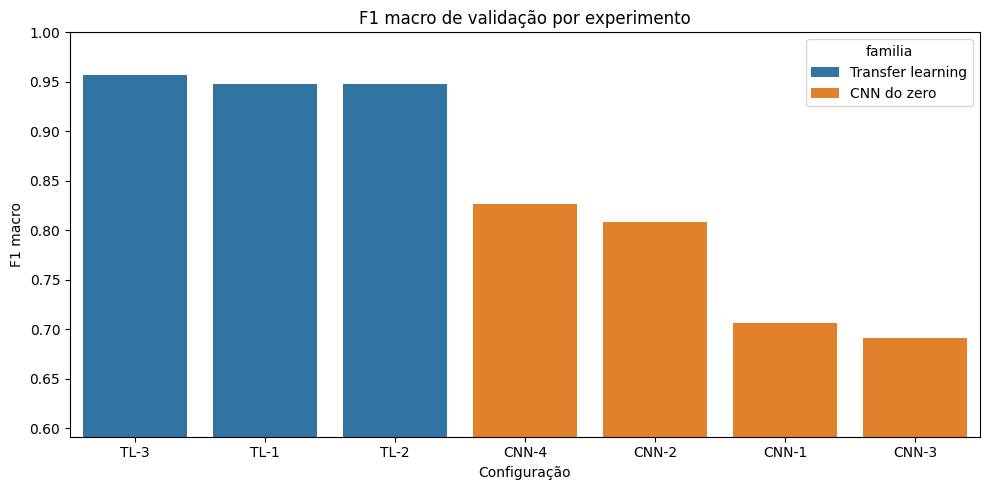

In [15]:
if EXECUTAR_EXPERIMENTOS:
    all_results_df = pd.concat(
        [scratch_results_df, transfer_results_df], ignore_index=True
    ).sort_values("val_f1_macro", ascending=False)
    display(all_results_df)
    all_results_df.to_csv(
        RESULTS_DIR / "comparacao_todos_experimentos.csv", index=False
    )

    plt.figure(figsize=(10, 5))
    sns.barplot(
        data=all_results_df,
        x="experimento",
        y="val_f1_macro",
        hue="familia",
    )
    plt.ylim(max(0, all_results_df["val_f1_macro"].min() - 0.10), 1.0)
    plt.title("F1 macro de validação por experimento")
    plt.ylabel("F1 macro")
    plt.xlabel("Configuração")
    plt.tight_layout()
    plt.savefig(
        FIGURES_DIR / "comparacao_experimentos_validacao.png",
        dpi=160,
        bbox_inches="tight",
    )
    plt.show()

## 10. Avaliação final no teste reservado

Somente o melhor modelo de cada família é avaliado no teste. Essa decisão metodológica evita selecionar hiperparâmetros com base no resultado final. São calculadas métricas macro, relatório por classe e matriz de confusão.

In [16]:
def evaluate_test(model, model_name):
    probabilities = model.predict(test_ds, verbose=0)
    predictions = np.argmax(probabilities, axis=1)
    metrics = {
        "modelo": model_name,
        "test_accuracy": accuracy_score(y_test, predictions),
        "test_precision_macro": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "test_recall_macro": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "test_f1_macro": f1_score(
            y_test, predictions, average="macro", zero_division=0
        ),
    }
    report = classification_report(
        y_test,
        predictions,
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0,
    )
    report_df = pd.DataFrame(report).T
    cm = confusion_matrix(y_test, predictions)
    return metrics, report_df, cm, predictions, probabilities


if EXECUTAR_EXPERIMENTOS:
    final_evaluations = {}
    final_metrics = []
    for model_name, model in {
        best_scratch_id: best_scratch_model,
        best_transfer_id: best_transfer_model,
    }.items():
        outputs = evaluate_test(model, model_name)
        final_evaluations[model_name] = outputs
        final_metrics.append(outputs[0])
        outputs[1].to_csv(RESULTS_DIR / f"relatorio_teste_{model_name}.csv")

    final_metrics_df = pd.DataFrame(final_metrics).sort_values(
        "test_f1_macro", ascending=False
    )
    display(final_metrics_df)
    final_metrics_df.to_csv(RESULTS_DIR / "metricas_finais_teste.csv", index=False)

,modelo,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro
1,TL-3,0.962963,0.961715,0.962111,0.961802
0,CNN-4,0.834074,0.829036,0.829578,0.825176


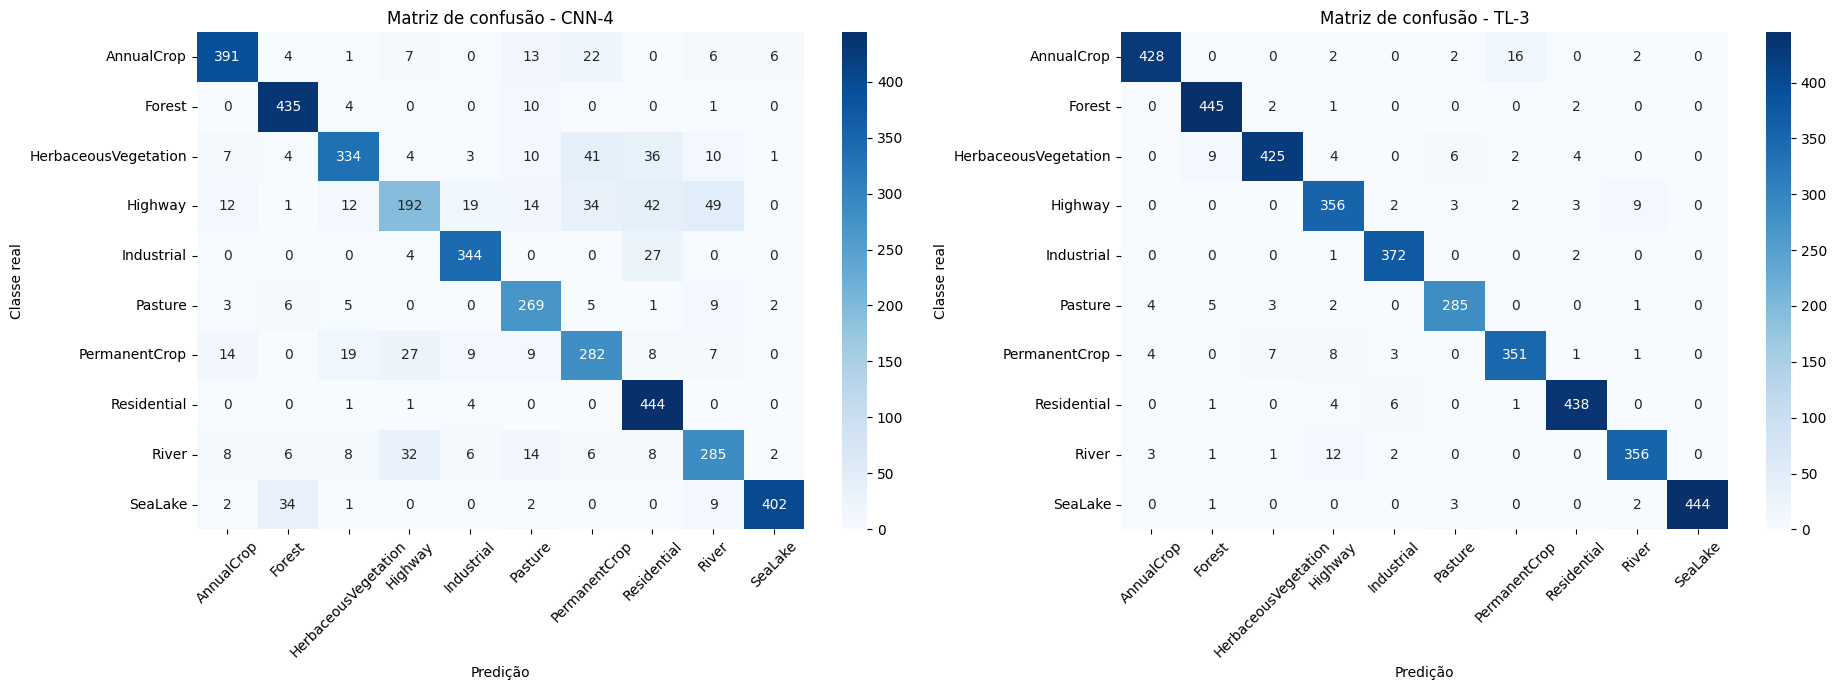

In [17]:
if EXECUTAR_EXPERIMENTOS:
    fig, axes = plt.subplots(1, 2, figsize=(19, 7))
    for ax, (model_name, outputs) in zip(axes, final_evaluations.items()):
        cm = outputs[2]
        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES,
            ax=ax,
        )
        ax.set_title(f"Matriz de confusão - {model_name}")
        ax.set_xlabel("Predição")
        ax.set_ylabel("Classe real")
        ax.tick_params(axis="x", rotation=45)
        ax.tick_params(axis="y", rotation=0)
    plt.tight_layout()
    plt.savefig(
        FIGURES_DIR / "matrizes_confusao_modelos_selecionados.png",
        dpi=160,
        bbox_inches="tight",
    )
    plt.show()

### 10.1 Exemplos de erros do melhor modelo geral

Erros individuais ajudam a interpretar as métricas. O painel mostra amostras incorretas, com classe real e prevista. Confusões entre padrões visualmente semelhantes devem ser discutidas em conjunto com a matriz de confusão.

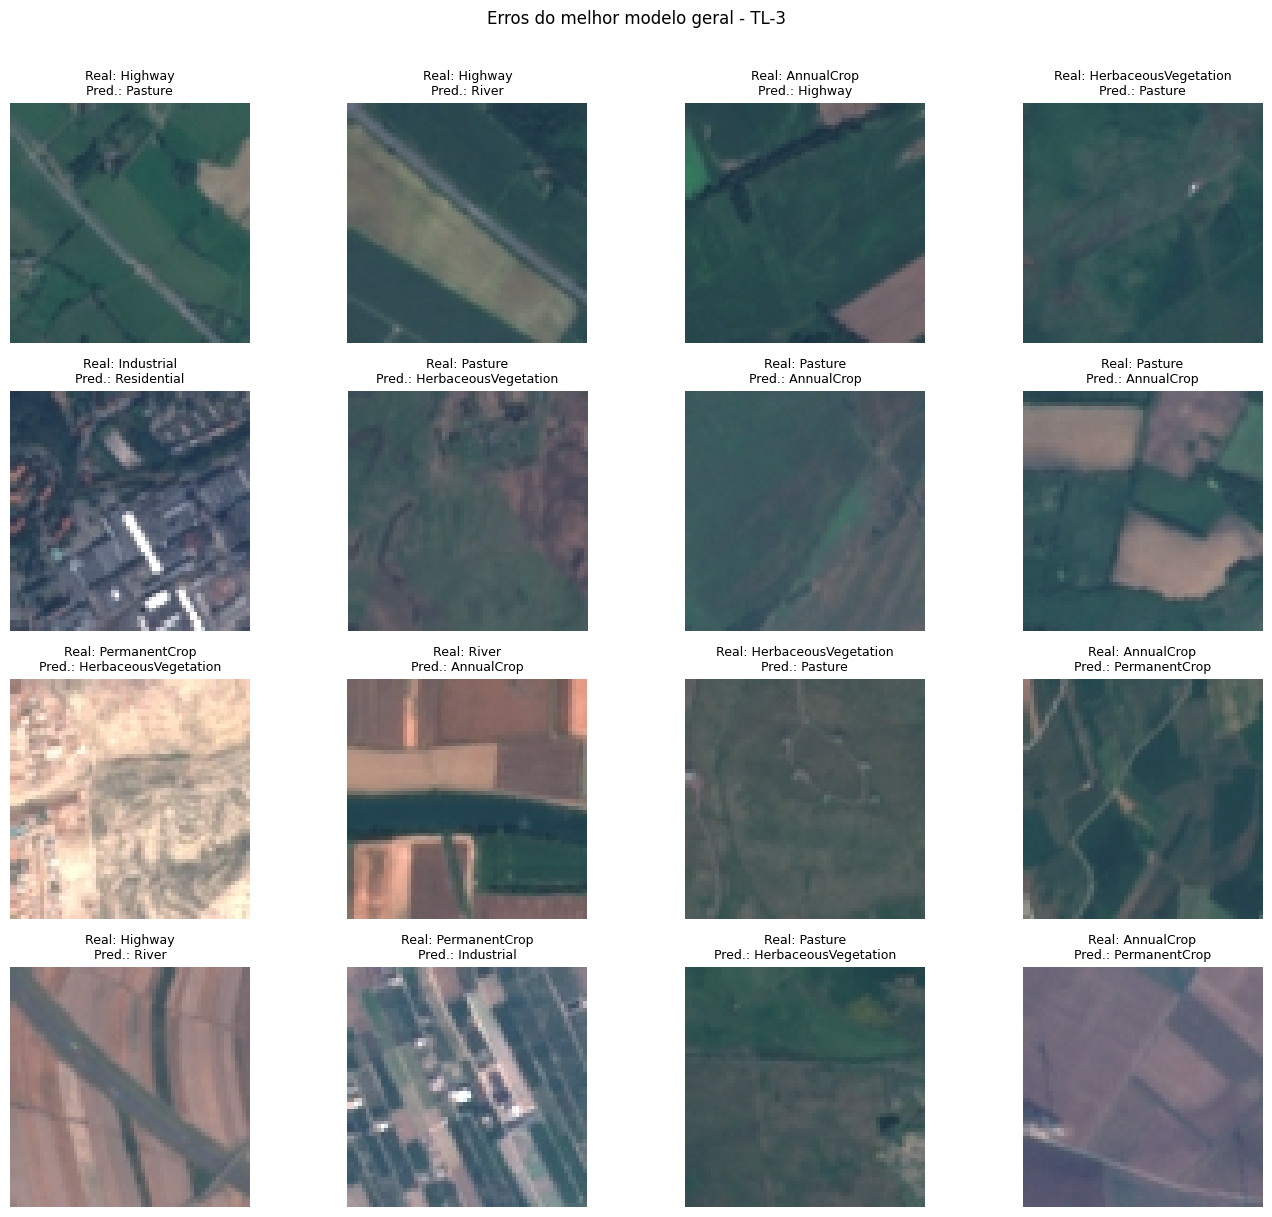

In [18]:
if EXECUTAR_EXPERIMENTOS:
    best_overall_name = final_metrics_df.iloc[0]["modelo"]
    best_outputs = final_evaluations[best_overall_name]
    test_predictions = best_outputs[3]

    test_images = np.concatenate(
        [images.numpy() for images, _ in test_ds], axis=0
    )
    wrong_indices = np.where(test_predictions != y_test)[0][:16]

    if len(wrong_indices):
        plt.figure(figsize=(14, 12))
        for plot_index, sample_index in enumerate(wrong_indices):
            ax = plt.subplot(4, 4, plot_index + 1)
            ax.imshow(test_images[sample_index])
            real = CLASS_NAMES[int(y_test[sample_index])]
            predicted = CLASS_NAMES[int(test_predictions[sample_index])]
            ax.set_title(f"Real: {real}\nPred.: {predicted}", fontsize=9)
            ax.axis("off")
        plt.suptitle(f"Erros do melhor modelo geral - {best_overall_name}", y=1.01)
        plt.tight_layout()
        plt.savefig(
            FIGURES_DIR / "exemplos_erros_melhor_modelo.png",
            dpi=160,
            bbox_inches="tight",
        )
        plt.show()

## 11. Exportação dos modelos e síntese automática

Os pesos dos modelos selecionados são exportados em arquivos `.weights.h5`. Eles podem ser recriados integralmente pelo notebook; por isso, os arquivos grandes não precisam ser versionados no Git.

In [19]:
if EXECUTAR_EXPERIMENTOS:
    # Pesos evitam diferenças de serialização entre versões do Keras;
    # as arquiteturas permanecem integralmente descritas neste notebook.
    best_scratch_model.save_weights(
        MODELS_DIR / "melhor_cnn_zero.weights.h5"
    )
    best_transfer_model.save_weights(
        MODELS_DIR / "melhor_resnet50_transfer.weights.h5"
    )

    summary_payload = {
        "dataset": "EuroSAT RGB",
        "seed": SEED,
        "classes": CLASS_NAMES,
        "melhor_cnn_zero": best_scratch_id,
        "melhor_transfer_learning": best_transfer_id,
        "melhor_modelo_geral_no_teste": best_overall_name,
        "metricas_finais": final_metrics_df.to_dict(orient="records"),
        "observacao": (
            "O teste foi consultado apenas após a seleção pela validação. "
            "Os resultados medem generalização interna, não geográfica."
        ),
    }
    with open(RESULTS_DIR / "resumo_execucao.json", "w", encoding="utf-8") as stream:
        json.dump(summary_payload, stream, ensure_ascii=False, indent=2)

    display(pd.DataFrame(summary_payload["metricas_finais"]))

,modelo,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro
0,TL-3,0.962963,0.961715,0.962111,0.961802
1,CNN-4,0.834074,0.829036,0.829578,0.825176


## 12. Conclusões

O trabalho comparou uma CNN desenvolvida do zero e uma ResNet50 pré-treinada sob um protocolo comum. A análise deve considerar quatro aspectos:

1. **Desempenho:** comparar F1 macro e acurácia dos dois modelos selecionados.
2. **Generalização:** observar a distância entre curvas de treino e validação e o resultado no teste.
3. **Custo:** contrastar parâmetros treináveis e tempo dos experimentos.
4. **Erros:** identificar classes visualmente semelhantes e padrões recorrentes na matriz de confusão.

A CNN-2 alcançou **81,93% de acurácia** e **81,22% de F1 macro** no teste. A TL-3, obtida pelo fine-tuning das 30 últimas camadas da ResNet50, alcançou **96,10% de acurácia** e **95,98% de F1 macro**. O ganho de **14,76 pontos percentuais em F1 macro** favorece o transfer learning neste protocolo. A TL-3 também manteve F1 por classe entre 93,69% (`PermanentCrop`) e 98,99% (`SeaLake`), indicando desempenho consistente, embora não perfeito.

### Limitações

- Foram utilizadas apenas as três bandas RGB, não as 13 bandas Sentinel-2 disponíveis na versão multiespectral.
- A divisão aleatória não comprova generalização para países, estações ou regiões geográficas novas.
- Recortes espacialmente próximos podem compartilhar texturas e aumentar as métricas internas.
- As classes representam categorias do dataset; uma aplicação territorial real exigiria validação externa.